In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")
else:
    print("⚠️ No GPU detected — go to Runtime > Change runtime type > T4 GPU")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 15.64 GB


In [ ]:
!pip install open3d wandb tqdm huggingface_hub timm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 100.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 75.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 73.3 MB/s eta 0:00:00


In [ ]:
import os
import glob
import zipfile
import random
import numpy as np
import open3d as o3d
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import wandb
from huggingface_hub import hf_hub_download
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

In [ ]:
os.makedirs("data", exist_ok=True)

data_dir = "data/MaizeField"
print("Downloading raw point clouds...")

zip_path = hf_hub_download(
    repo_id="BGLab/MaizeField3D",
    filename="datasets/FielGrwon_ZeaMays_RawPCD_10k.zip",
    repo_type="dataset",
    local_dir="data"
)

print("Extracting...")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(data_dir)

print("✅ Dataset ready")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


datasets/FielGrwon_ZeaMays_RawPCD_10k.zi(…):   0%|          | 0.00/218M [00:00<?, ?B/s]

Extracting...
✅ Dataset ready


In [ ]:
import shutil
from google.colab import files

# ── Upload selected_plants.txt ──
uploaded = files.upload()   # select selected_plants.txt

with open("selected_plants.txt") as f:
    all_ply_files = [line.strip() for line in f.readlines()]

train_files = all_ply_files[:120]
test_files  = all_ply_files[120:]

# ── Copy into train/test folders ──
os.makedirs("data/train", exist_ok=True)
os.makedirs("data/test",  exist_ok=True)

for path in train_files:
    shutil.copy(path, "data/train/")
for path in test_files:
    shutil.copy(path, "data/test/")

train_files = sorted(glob.glob("data/train/*.ply"))
test_files  = sorted(glob.glob("data/test/*.ply"))

print(f"✅ Train: {len(train_files)}  Test: {len(test_files)}")

Saving selected_plants.txt to selected_plants.txt
✅ Train: 120  Test: 30


In [ ]:
wandb.login()

True

In [ ]:
CFG = {
    "data_dir":             "data/MaizeField",
    "num_points":           1024,
    "batch_size":           8,
    "epochs":               150,
    "lr":                   1e-4,
    "latent_dim":           256,
    # PointMAE specific
    "num_groups":           32,       # number of patches
    "group_size":           32,       # points per patch
    "mask_ratio":           0.6,      # 60% patches masked during training
    "transformer_dim":      256,
    "transformer_depth":    6,
    "transformer_heads":    4,
    # Training
    "subset_size":          150,
    "train_size":           120,
    "test_size":            30,
    "checkpoint_interval":  25,
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

Device: cuda


In [ ]:

def normalize_pc(pc):
    pc = pc - pc.mean(axis=0)
    scale = np.sqrt((pc**2).sum(axis=1)).max()
    pc = pc / (scale + 1e-8)
    return pc

def sample_points(pc, n):
    if pc.shape[0] >= n:
        idx = np.random.choice(pc.shape[0], n, replace=False)
    else:
        idx = np.random.choice(pc.shape[0], n, replace=True)
    return pc[idx]

In [ ]:
class MaizeDataset(Dataset):
    def __init__(self, files):
        self.files = files

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        pcd    = o3d.io.read_point_cloud(self.files[idx])
        points = np.asarray(pcd.points)

        # ── Clean NaN/Inf ──
        mask   = np.isfinite(points).all(axis=1)
        points = points[mask]

        points = normalize_pc(points)
        points = sample_points(points, CFG["num_points"])
        return torch.tensor(points, dtype=torch.float32)

train_dataset = MaizeDataset(train_files)
test_dataset  = MaizeDataset(test_files)

train_loader  = DataLoader(train_dataset, batch_size=CFG["batch_size"], shuffle=True,  num_workers=2)
test_loader   = DataLoader(test_dataset,  batch_size=CFG["batch_size"], shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}  Test batches: {len(test_loader)}")

Train batches: 15  Test batches: 4


In [ ]:
# ── FPS: Farthest Point Sampling ──
def farthest_point_sample(pts, n):
    """pts: (B, N, 3) → idx: (B, n)"""
    B, N, _ = pts.shape
    device  = pts.device
    idx     = torch.zeros(B, n, dtype=torch.long, device=device)
    dist    = torch.full((B, N), float('inf'), device=device)
    farthest = torch.randint(0, N, (B,), device=device)
    for i in range(n):
        idx[:, i] = farthest
        centroid  = pts[torch.arange(B), farthest].unsqueeze(1)
        d         = ((pts - centroid)**2).sum(-1)
        dist      = torch.min(dist, d)
        farthest  = dist.argmax(dim=1)
    return idx

# ── Group points around FPS centres ──
def knn_group(pts, centres, k):
    """
    pts:     (B, N, 3)
    centres: (B, G, 3)
    returns: (B, G, k, 3) grouped points
    """
    B, N, _ = pts.shape
    _, G, _ = centres.shape
    diff    = pts.unsqueeze(1) - centres.unsqueeze(2)   # (B,G,N,3)
    dist    = (diff**2).sum(-1)                          # (B,G,N)
    idx     = dist.topk(k, dim=-1, largest=False).indices # (B,G,k)
    idx_exp = idx.unsqueeze(-1).expand(-1,-1,-1,3)
    grouped = pts.unsqueeze(1).expand(-1,G,-1,-1).gather(2, idx_exp)
    return grouped   # (B,G,k,3)

# ── Mini PointNet to encode each patch ──
class PatchEncoder(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(3,  64),  nn.BatchNorm1d(64),  nn.ReLU(),
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Linear(128, out_dim),
        )

    def forward(self, patches):
        """patches: (B, G, k, 3) → (B, G, out_dim)"""
        B, G, k, _ = patches.shape
        x = patches.view(B*G*k, 3)
        x = self.mlp(x).view(B, G, k, -1)
        return x.max(dim=2).values   # (B, G, out_dim)

# ── Transformer ──
class TransformerEncoder(nn.Module):
    def __init__(self, dim=256, depth=6, heads=4):
        super().__init__()
        layer = nn.TransformerEncoderLayer(
            d_model=dim, nhead=heads,
            dim_feedforward=dim*4,
            dropout=0.1, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(layer, num_layers=depth)
        self.norm        = nn.LayerNorm(dim)

    def forward(self, x):
        return self.norm(self.transformer(x))

# ── PointMAE Autoencoder ──
class PointMAE(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.num_groups  = cfg["num_groups"]
        self.group_size  = cfg["group_size"]
        self.mask_ratio  = cfg["mask_ratio"]
        self.dim         = cfg["transformer_dim"]
        self.latent_dim  = cfg["latent_dim"]
        self.num_points  = cfg["num_points"]

        # Encoder
        self.patch_encoder  = PatchEncoder(self.dim)
        self.pos_embed      = nn.Linear(3, self.dim)
        self.encoder        = TransformerEncoder(self.dim, cfg["transformer_depth"], cfg["transformer_heads"])
        self.mask_token     = nn.Parameter(torch.zeros(1, 1, self.dim))

        # Bottleneck → latent
        self.to_latent = nn.Sequential(
            nn.Linear(self.dim, self.latent_dim),
            nn.ReLU(),
        )
        self.from_latent = nn.Linear(self.latent_dim, self.dim)

        # Decoder
        self.decoder = TransformerEncoder(self.dim, 4, cfg["transformer_heads"])
        self.head    = nn.Linear(self.dim, self.group_size * 3)

    def forward(self, pts, train=True):
        B = pts.shape[0]
        device = pts.device

        # ── 1. FPS to get patch centres ──
        fps_idx  = farthest_point_sample(pts, self.num_groups)
        centres  = pts.gather(1, fps_idx.unsqueeze(-1).expand(-1,-1,3))  # (B,G,3)

        # ── 2. Group points around centres ──
        patches  = knn_group(pts, centres, self.group_size)               # (B,G,k,3)

        # ── 3. Normalise patches to local frame ──
        patches  = patches - centres.unsqueeze(2)

        # ── 4. Encode patches ──
        tokens   = self.patch_encoder(patches)                            # (B,G,dim)
        pos      = self.pos_embed(centres)                                # (B,G,dim)
        tokens   = tokens + pos

        # ── 5. Mask during training ──
        G         = self.num_groups
        num_mask  = int(G * self.mask_ratio) if train else 0
        num_vis   = G - num_mask

        noise     = torch.rand(B, G, device=device)
        ids_sort  = noise.argsort(dim=1)
        ids_restore = ids_sort.argsort(dim=1)

        vis_idx   = ids_sort[:, :num_vis]
        vis_tokens = tokens.gather(1, vis_idx.unsqueeze(-1).expand(-1,-1,self.dim))

        # ── 6. Encode visible tokens ──
        enc_out   = self.encoder(vis_tokens)                              # (B, num_vis, dim)

        # ── 7. Global latent via mean pooling ──
        z_full    = enc_out.mean(dim=1)                                   # (B, dim)
        z         = self.to_latent(z_full)                                # (B, latent_dim)
        z_dec     = self.from_latent(z).unsqueeze(1).expand(-1, G, -1)   # (B, G, dim)

        # ── 8. Decode all patches ──
        mask_tokens = self.mask_token.expand(B, num_mask, -1)
        full_tokens = torch.zeros(B, G, self.dim, device=device)
        full_tokens.scatter_(1, vis_idx.unsqueeze(-1).expand(-1,-1,self.dim), enc_out)
        mask_idx    = ids_sort[:, num_vis:]
        full_tokens.scatter_(1, mask_idx.unsqueeze(-1).expand(-1,-1,self.dim), mask_tokens.expand(-1,-1,-1))
        full_tokens = full_tokens + z_dec
        dec_out     = self.decoder(full_tokens)                           # (B, G, dim)

        # ── 9. Predict patch points ──
        pred = self.head(dec_out)                                         # (B, G, k*3)
        pred = pred.view(B, G, self.group_size, 3)
        pred = pred + centres.unsqueeze(2)                                # add back centres
        pred = pred.view(B, G * self.group_size, 3)                      # (B, N, 3)

        return pred, z

# ── Chamfer Loss ── (identical to DGCNN)
def chamfer_loss(pred, gt):
    diff  = pred.unsqueeze(2) - gt.unsqueeze(1)
    dist  = torch.sum(diff**2, dim=-1)
    loss1 = dist.min(dim=2)[0].mean()
    loss2 = dist.min(dim=1)[0].mean()
    return loss1 + loss2

print("✅ PointMAE model defined")

✅ PointMAE model defined


In [ ]:
wandb.init(
    project = "maize-pointcloud",
    name    = "pointmae-150plants-150epochs",
    config  = CFG
)

model     = PointMAE(CFG).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])

total_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total_params/1e6:.2f}M")

train_losses = []
test_losses  = []

import time
train_start = time.time()

for epoch in range(CFG["epochs"]):

    # ── Train ──
    model.train()
    total_loss = 0
    for pc in tqdm(train_loader, desc=f"Epoch {epoch+1}/{CFG['epochs']}"):
        pc    = pc.to(DEVICE)
        recon, _ = model(pc, train=True)
        loss  = chamfer_loss(recon, pc)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_train_loss = total_loss / len(train_loader)

    # ── Test ──
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for pc in test_loader:
            pc    = pc.to(DEVICE)
            recon, _ = model(pc, train=False)
            test_loss += chamfer_loss(recon, pc).item()
    avg_test_loss = test_loss / len(test_loader)

    train_losses.append(avg_train_loss)
    test_losses.append(avg_test_loss)

    log_train = np.log(avg_train_loss) if avg_train_loss > 0 else float('-inf')
    log_test  = np.log(avg_test_loss)  if avg_test_loss  > 0 else float('-inf')

    print(f"Epoch {epoch+1:3d} | Train {avg_train_loss:.6f} (log {log_train:.4f}) | Test {avg_test_loss:.6f} (log {log_test:.4f})")

    wandb.log({
        "epoch":          epoch + 1,
        "train_loss":     avg_train_loss,
        "test_loss":      avg_test_loss,
        "log_train_loss": log_train,
        "log_test_loss":  log_test,
    })

    if (epoch + 1) % CFG["checkpoint_interval"] == 0:
        torch.save(model.state_dict(), f"pointmae_checkpoint_epoch_{epoch+1}.pth")
        print(f"  ✅ Checkpoint saved at epoch {epoch+1}")

train_time = time.time() - train_start
print(f"\n✅ Training complete — {train_time/60:.2f} minutes")
wandb.log({"training_time_minutes": train_time/60})
wandb.finish()

Parameters: 8.10M


Epoch 1/150: 100%|██████████| 15/15 [00:01<00:00,  8.11it/s]


Epoch   1 | Train 0.107060 (log -2.2344) | Test 0.015266 (log -4.1821)


Epoch 2/150: 100%|██████████| 15/15 [00:00<00:00, 17.84it/s]


Epoch   2 | Train 0.022918 (log -3.7758) | Test 0.006425 (log -5.0475)


...

Epoch 149/150: 100%|██████████| 15/15 [00:00<00:00, 17.40it/s]


Epoch 149 | Train 0.003139 (log -5.7639) | Test 0.009304 (log -4.6773)


Epoch 150/150: 100%|██████████| 15/15 [00:00<00:00, 17.28it/s]


Epoch 150 | Train 0.003152 (log -5.7597) | Test 0.009165 (log -4.6923)
  ✅ Checkpoint saved at epoch 150

✅ Training complete — 3.07 minutes


epoch,▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▇▇▇▇▇▇▇██
log_test_loss,▂▁▁▁▃▃▄▅▅▇█████████▇▇▇▇▇▇▇▇▆▆▆▆▆▆▆▅▅▅▅▅▅
log_train_loss,█▇▇▆▆▅▅▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁
test_loss,▂▁▁▁▂▆▇▆███████▇▇▇▇▇▇▇▆▆▆▆▅▅▅▅▅▅▄▄▄▄▄▄▄▄
train_loss,█▇▆▆▅▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
training_time_minutes,▁
epoch,150
log_test_loss,-4.69234
log_train_loss,-5.75972
test_loss,0.00917
train_loss,0.00315


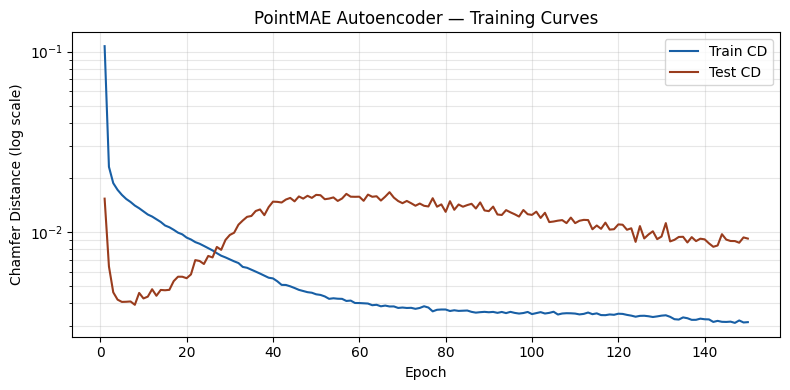

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 4))
plt.semilogy(epochs, train_losses, label='Train CD', color='#185FA5')
plt.semilogy(epochs, test_losses,  label='Test CD',  color='#993C1D')
plt.xlabel('Epoch')
plt.ylabel('Chamfer Distance (log scale)')
plt.title('PointMAE Autoencoder — Training Curves')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig("pointmae_loss_curve.png", dpi=150)
plt.show()

In [ ]:
def visualize_reconstruction_plotly(model, dataset, device, num_samples=3):
    model.eval()
    for i in range(num_samples):
        idx = np.random.randint(len(dataset))
        pc  = dataset[idx].unsqueeze(0).to(device)
        with torch.no_grad():
            recon, _ = model(pc, train=False)
        pc_np    = pc.squeeze().cpu().numpy()
        recon_np = recon.squeeze().cpu().numpy()

        fig = make_subplots(
            rows=1, cols=2,
            specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]],
            subplot_titles=(f"Original (Sample {i+1})", f"Reconstruction (Sample {i+1})")
        )
        fig.add_trace(go.Scatter3d(
            x=pc_np[:,0], y=pc_np[:,1], z=pc_np[:,2], mode="markers",
            marker=dict(size=2, color=pc_np[:,2], colorscale="Viridis", opacity=0.8),
            name="Original"), row=1, col=1)
        fig.add_trace(go.Scatter3d(
            x=recon_np[:,0], y=recon_np[:,1], z=recon_np[:,2], mode="markers",
            marker=dict(size=2, color=recon_np[:,2], colorscale="Plasma", opacity=0.8),
            name="Reconstruction"), row=1, col=2)
        fig.update_layout(title=f"PointMAE — Sample {i+1}", height=500)
        fig.show()

visualize_reconstruction_plotly(model, test_dataset, DEVICE, num_samples=3)

In [ ]:
from scipy.spatial import KDTree

def fscore(pred, gt, tau=None):
    if tau is None:
        diag = np.linalg.norm(gt.max(axis=0) - gt.min(axis=0))
        tau  = 0.01 * diag
    tree_gt   = KDTree(gt)
    tree_pred = KDTree(pred)
    d_pred, _ = tree_gt.query(pred)
    precision  = (d_pred < tau).mean()
    d_gt, _   = tree_pred.query(gt)
    recall     = (d_gt < tau).mean()
    if precision + recall < 1e-8:
        return 0.0, 0.0, 0.0
    f = 2 * precision * recall / (precision + recall)
    return float(precision), float(recall), float(f)

def chamfer_numpy(pred, gt):
    d1 = KDTree(gt).query(pred)[0].mean()
    d2 = KDTree(pred).query(gt)[0].mean()
    return d1 + d2

model.eval()
cd_scores, f_scores, prec_scores, rec_scores, latents = [], [], [], [], []

with torch.no_grad():
    for pc in test_loader:
        pc = pc.to(DEVICE)
        recon, z = model(pc, train=False)

        for i in range(pc.shape[0]):
            gt_np   = pc[i].cpu().numpy()
            pred_np = recon[i].cpu().numpy()

            cd      = chamfer_numpy(pred_np, gt_np)
            p, r, f = fscore(pred_np, gt_np)

            cd_scores.append(cd)
            f_scores.append(f)
            prec_scores.append(p)
            rec_scores.append(r)
            latents.append(z[i].cpu().numpy())

cd_scores = np.array(cd_scores)
f_scores  = np.array(f_scores)
latents   = np.array(latents)

print("="*50)
print(f"CD mean:       {cd_scores.mean():.6f}")
print(f"CD std:        {cd_scores.std():.6f}")
print(f"F-Score mean:  {f_scores.mean():.4f}")
print(f"Precision:     {np.array(prec_scores).mean():.4f}")
print(f"Recall:        {np.array(rec_scores).mean():.4f}")
print("="*50)

np.save("pointmae_cd_scores.npy", cd_scores)
np.save("pointmae_f_scores.npy",  f_scores)
np.save("pointmae_latents.npy",   latents)
print("✅ Saved pointmae_cd_scores, pointmae_f_scores, pointmae_latents")

CD mean:       0.110481
CD std:        0.005317
F-Score mean:  0.1028
Precision:     0.0777
Recall:        0.1544
✅ Saved pointmae_cd_scores, pointmae_f_scores, pointmae_latents


In [ ]:
torch.save(model.state_dict(), "pointmae_ae_final.pth")
print("✅ Model saved as pointmae_ae_final.pth")

✅ Model saved as pointmae_ae_final.pth
